In [1]:
import pandas as pd, sklearn
print("OK", pd.__version__, sklearn.__version__)

OK 3.1.1 1.9.1


In [2]:
import pandas as pd

df = pd.read_excel("20250326-Vocabulary_Search_Behavior_Information_Dataset.xlsx")

print("行数・列数：", df.shape)
print("\n列名：")
for i, c in enumerate(df.columns):
    print(i, c)

df.head()

行数・列数： (4712, 25)

列名：
0 ①大学ID
1 ②個人ID
2 ③★追加タグ★
日本語レベル
3 
④調べたい言葉（語/句/文）
4 ⑤★追加タグ★
（D列の）調べたい言葉の語種
5 ⑥実際に
調べたか（調べた〇、調べていない×）
6 ⑦★追加タグ★
行動種類
7 
⑧調べた日
（調べたいと思った日）
8 ⑨調べた場所
9 ⑩どこで見た／聞いた言葉か
10 ⑪知りたい内容
（読み、発音、
意味、用法など）
11 ⑫★追加タグ★
（K列の）知りたい内容
12 ⑬検索の具体的な状況
13 ⑭入力内容
14 ⑮★追加タグ★
（N列の）入力内容の言語
15 ⑯使用ツール
（スマホ、PC、タブレットなど）
16 ⑰使用したアプリ名・辞書名・サイト名等
例：imiwa?、Jisho.org、MOJi辞書、네이버사전（NAVER、diction）大辞林
17 ⑱★追加タグ★
（Q列の）使用した辞書リソース
18 ⑲WebまたはApp
19 ⑳入力方法
20 ㉑T列で、「その他」を選んだ場合、記入してください
OCR入力（画像入力）を使用した場合は、OCRと書いてください。
21 ㉒★追加タグ★
（T・U列の）入力方法
22 ㉓目的が達成できたか
23 ㉔W列で、「達成できた」以外を選択した場合の理由
24 ㉕F列が×の場合
（実際に調べなかった理由）


,①大学ID,②個人ID,③★追加タグ★\n日本語レベル,\n④調べたい言葉（語/句/文）,⑤★追加タグ★\n（D列の）調べたい言葉の語種,⑥実際に\n調べたか（調べた〇、調べていない×）,⑦★追加タグ★\n行動種類,\n⑧調べた日\n（調べたいと思った日）,⑨調べた場所,⑩どこで見た／聞いた言葉か,...,⑯使用ツール\n（スマホ、PC、タブレットなど）,⑰使用したアプリ名・辞書名・サイト名等\n例：imiwa?、Jisho.org、MOJi辞書、네이버사전（NAVER、diction）大辞林,⑱★追加タグ★\n（Q列の）使用した辞書リソース,⑲WebまたはApp,⑳入力方法,㉑T列で、「その他」を選んだ場合、記入してください\nOCR入力（画像入力）を使用した場合は、OCRと書いてください。,㉒★追加タグ★\n（T・U列の）入力方法,㉓目的が達成できたか,㉔W列で、「達成できた」以外を選択した場合の理由,㉕F列が×の場合\n（実際に調べなかった理由）
0,ccq,dic_ccq002,03_中上級,土砂降り,04_混種語,○,01_単独,2022-02-25 00:00:00,自宅,ドラマのセリフ,...,スマホ,MOJi辞書,01_MOJi辞書,App,手書き入力,NaN,02_手書き入力,達成できた,NaN,NaN
1,ccq,dic_ccq002,03_中上級,漂う,01_和語,○,01_単独,2022-02-25 00:00:00,自宅,ドラマのセリフ,...,スマホ,MOJi辞書,01_MOJi辞書,App,キーボード入力,NaN,01_キーボード入力,達成できた,NaN,NaN
2,ccq,dic_ccq002,03_中上級,途切れる,01_和語,○,01_単独,2022-02-25 00:00:00,自宅,ドラマのセリフ,...,スマホ,MOJi辞書,01_MOJi辞書,App,キーボード入力,NaN,01_キーボード入力,達成できた,NaN,NaN
3,ccq,dic_ccq002,03_中上級,けだるい,01_和語,○,01_単独,2022-02-25 00:00:00,自宅,ドラマのセリフ,...,スマホ,MOJi辞書,01_MOJi辞書,App,キーボード入力,NaN,01_キーボード入力,達成できた,NaN,NaN
4,ccq,dic_ccq002,03_中上級,両替,04_混種語,○,01_単独,2022-02-25 00:00:00,自宅,ドラマのセリフ,...,スマホ,MOJi辞書,01_MOJi辞書,App,キーボード入力,NaN,01_キーボード入力,達成できた,NaN,NaN


In [3]:
# 1) 列名换成简短英文（顺序和原表 A〜Y 列一致）
df.columns = [
    "univ_id", "person_id", "jp_level", "target_word", "word_type",
    "searched", "action_type", "date", "place", "source",
    "want_raw", "want_tag", "situation", "input_text", "input_lang",
    "tool", "app_name", "resource_tag", "web_app",
    "input_method_raw", "input_method_other", "input_method_tag",
    "achieved", "fail_reason", "not_search_reason"
]

# 2) 基本情况
print("学习者人数：", df["person_id"].nunique())
print("大学数：", df["univ_id"].nunique())

# 3) 关键列里有哪些值、各有多少条
for col in ["jp_level", "searched", "action_type", "input_lang",
            "resource_tag", "web_app", "input_method_tag", "achieved"]:
    print("\n=====", col, "=====")
    print(df[col].value_counts(dropna=False).head(15))

学习者人数： 110
大学数： 9

===== jp_level =====
jp_level
03_中上級    1666
02_中級     1229
01_初級      934
04_上級      883
Name: count, dtype: int64

===== searched =====
searched
○      3629
NaN     994
×        89
Name: count, dtype: int64

===== action_type =====
action_type
01_単独      2964
02_連続1      630
02_連続2      630
02_連続3      225
02_連続4       90
03_該当なし      89
02_連続5       42
02_連続6       18
02_連続7        9
02_連続8        7
02_連続9        3
02_連続10       1
02_連続11       1
02_連続12       1
02_連続13       1
Name: count, dtype: int64

===== input_lang =====
input_lang
01_日本語            4189
11_該当なし            186
02_中国語             122
04_韓国語              99
03_英語               37
05_ベトナム語            18
10_日本語読み・韓国語表記      17
08_中国語＋日本語          12
06_ドイツ語             12
07_日本語＋英語            8
07_日本語＋中国語           7
07_日本語＋韓国語           3
09_韓国語＋日本語           1
07_日本語＋ベトナム語         1
Name: count, dtype: int64

===== resource_tag =====
resource_tag
01_MOJi辞書                          1033
02_Mazi

In [4]:
# ===== 数据清洗：统一写法 =====
import unicodedata

print("【清洗前】web_app 的值：")
print(df["web_app"].value_counts(dropna=False))

# 1) 全角→半角、去掉前后空格（对所有要用的列都做）
def clean(x):
    if pd.isna(x):
        return x
    return unicodedata.normalize("NFKC", str(x)).strip()

for col in ["action_type", "input_lang", "resource_tag",
            "web_app", "input_method_tag", "achieved"]:
    df[col] = df[col].map(clean)

# 2) 把 web_app 统一成 Web / App / その他 三类
def norm_webapp(x):
    if pd.isna(x):
        return x
    s = x.lower()
    if s in ("web", "ウェブ"):
        return "Web"
    if s in ("app", "アプリ"):
        return "App"
    return "その他"

df["web_app"] = df["web_app"].map(norm_webapp)

print("\n【清洗后】web_app 的值：")
print(df["web_app"].value_counts(dropna=False))

【清洗前】web_app 的值：
web_app
App     2815
Web     1518
NaN      288
アプリ       34
web       29
App       24
Web        2
紙の辞書       1
APP        1
Name: count, dtype: int64

【清洗后】web_app 的值：
web_app
App    2874
Web    1549
NaN     288
その他       1
Name: count, dtype: int64


In [5]:
# ===== 步骤1：按学习者汇总，做成“一人一行”的行为指标表 =====
import numpy as np

# 去掉“实际上没有查”（×）的记录，只用真正发生了检索的行
dfs = df[df["searched"] != "×"]

g = dfs.groupby("person_id")
feat = pd.DataFrame(index=g.size().index)

# 检索记录数（取对数，减弱“查得特别多的人”的影响）
feat["log_n_records"] = np.log1p(g.size())

# 连续检索的比例
feat["cont_ratio"] = g["action_type"].apply(lambda s: s.astype(str).str.contains("連続").mean())

# 目的达成率 / 未达成率（只看有回答的记录）
def rate(s, label):
    s = s.dropna()
    return (s == label).mean() if len(s) else np.nan
feat["achieved_rate"] = g["achieved"].apply(lambda s: rate(s, "達成できた"))
feat["failed_rate"]   = g["achieved"].apply(lambda s: rate(s, "達成できなかった"))

# 各类别的使用比例（每列取最常见的前4类，其余归为“その他”）
for col in ["input_lang", "resource_tag", "web_app", "input_method_tag"]:
    top = dfs[col].value_counts().index[:4]
    tmp = dfs[col].where(dfs[col].isin(top), "その他").fillna("その他")
    share = pd.crosstab(dfs["person_id"], tmp, normalize="index")
    share.columns = [f"{col}={c}" for c in share.columns]
    feat = feat.join(share)

feat = feat.fillna(feat.mean())

# 每位学习者的日语水平、所属大学
info = g[["jp_level", "univ_id"]].agg(lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)

print("学习者数 × 指标数：", feat.shape)
feat.round(2).head()

学习者数 × 指标数： (110, 22)


,log_n_records,cont_ratio,achieved_rate,failed_rate,input_lang=01_日本語,input_lang=02_中国語,input_lang=04_韓国語,input_lang=11_該当なし,input_lang=その他,resource_tag=01_MOJi辞書,...,resource_tag=04_Google,resource_tag=その他,web_app=App,web_app=Web,web_app=その他,input_method_tag=01_キーボード入力,input_method_tag=02_手書き入力,input_method_tag=03_コピペ入力,input_method_tag=05_クリック,input_method_tag=その他
person_id,,,,,,,,,,,,,,,,,,,,,
dic_ccq002,3.40,0.00,1.00,0.00,0.83,0.17,0.0,0.00,0.0,1.00,...,0.0,0.00,1.00,0.00,0.00,0.76,0.24,0.00,0.00,0.00
dic_ccq003,4.26,0.09,0.97,0.03,0.96,0.04,0.0,0.00,0.0,0.81,...,0.0,0.19,0.93,0.07,0.00,0.60,0.36,0.00,0.04,0.00
dic_ccq004,4.54,0.27,0.99,0.01,1.00,0.00,0.0,0.00,0.0,0.00,...,0.0,1.00,0.03,0.00,0.97,0.87,0.13,0.00,0.00,0.00
dic_ccq005,3.64,0.41,1.00,0.00,1.00,0.00,0.0,0.00,0.0,1.00,...,0.0,0.00,1.00,0.00,0.00,0.65,0.16,0.03,0.08,0.08
dic_ccq006,3.76,0.71,0.86,0.02,0.62,0.02,0.0,0.36,0.0,0.00,...,0.0,1.00,0.07,0.90,0.02,0.64,0.00,0.00,0.36,0.00


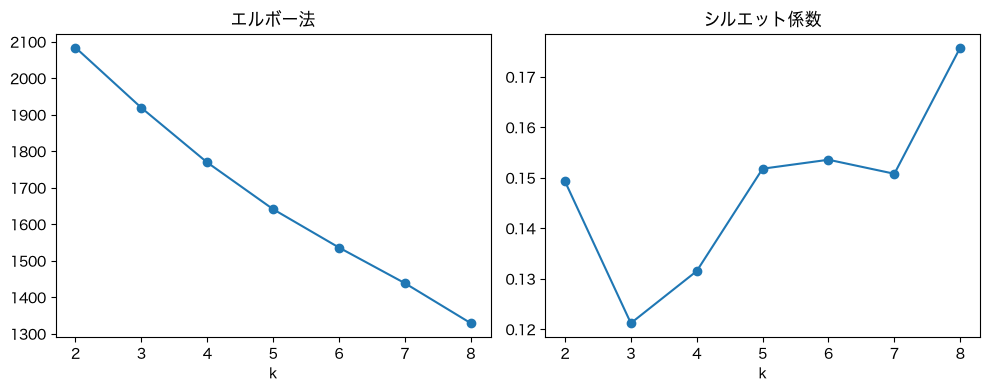

k=2  シルエット係数=0.149
k=3  シルエット係数=0.121
k=4  シルエット係数=0.131
k=5  シルエット係数=0.152
k=6  シルエット係数=0.154
k=7  シルエット係数=0.151
k=8  シルエット係数=0.176


In [6]:
# ===== 步骤2：标准化 + 决定分几类 =====
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

plt.rcParams["font.family"] = "Hiragino Sans"   # Mac 上显示日文

X = StandardScaler().fit_transform(feat)

ks = range(2, 9)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(X)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(list(ks), inertias, marker="o"); ax[0].set_title("エルボー法"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), sils, marker="o");     ax[1].set_title("シルエット係数"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

for k, s in zip(ks, sils):
    print(f"k={k}  シルエット係数={s:.3f}")

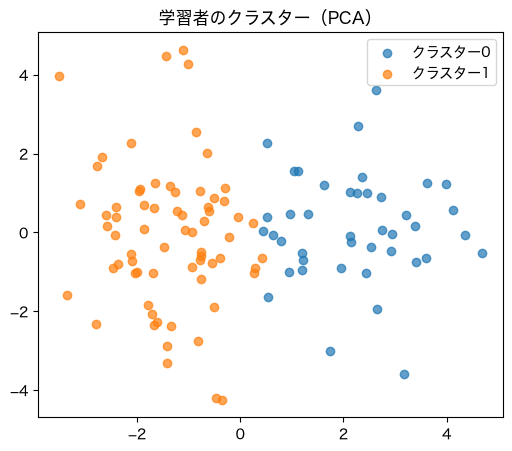

各クラスターの人数：
cluster
0    42
1    68
Name: count, dtype: int64


cluster,0,1
log_n_records,3.67,3.42
cont_ratio,0.57,0.18
achieved_rate,0.73,0.94
failed_rate,0.15,0.03
input_lang=01_日本語,0.84,0.89
input_lang=02_中国語,0.02,0.06
input_lang=04_韓国語,0.07,0.01
input_lang=11_該当なし,0.02,0.02
input_lang=その他,0.06,0.02
resource_tag=01_MOJi辞書,0.06,0.36


jp_level,01_初級,02_中級,03_中上級,04_上級
cluster,,,,
0,8,7,16,11
1,18,18,26,6


カイ二乗検定：χ²=6.77, 自由度=3, p=0.0796


univ_id,ccq,ccr,ctc,ega,gdb,jua,kkc,kke,vve
cluster,,,,,,,,,
0,5,6,9,1,0,4,7,6,4
1,23,14,2,2,3,9,4,5,6


In [7]:
# ===== 步骤3：聚类 → 看每类特征 → 和日语水平的关系 =====
from sklearn.decomposition import PCA
from scipy.stats import chi2_contingency

K = 2   # ← 先用3，看完步骤2的结果再改

km = KMeans(n_clusters=K, n_init=20, random_state=0).fit(X)
feat["cluster"] = km.labels_

pc = PCA(n_components=2).fit_transform(X)
plt.figure(figsize=(6, 5))
for c in range(K):
    m = feat["cluster"] == c
    plt.scatter(pc[m, 0], pc[m, 1], label=f"クラスター{c}", alpha=0.7)
plt.legend(); plt.title("学習者のクラスター（PCA）"); plt.show()

print("各クラスターの人数：")
print(feat["cluster"].value_counts().sort_index())
display(feat.groupby("cluster").mean().T.round(2))

ct = pd.crosstab(feat["cluster"], info["jp_level"])
display(ct)
chi2, p, dof, _ = chi2_contingency(ct)
print(f"カイ二乗検定：χ²={chi2:.2f}, 自由度={dof}, p={p:.4f}")

display(pd.crosstab(feat["cluster"], info["univ_id"]))

In [8]:
# ===== 大学 × 日语水平 =====
ct_ul = pd.crosstab(info["univ_id"], info["jp_level"], margins=True, margins_name="合計")
display(ct_ul)

# 各大学里“类0（Web探索型）”的比例
rate0 = feat.groupby(info["univ_id"])["cluster"].apply(lambda s: (s == 0).mean()).round(2)
print("各大学のWeb探索型の割合：")
print(rate0.sort_values(ascending=False))

jp_level,01_初級,02_中級,03_中上級,04_上級,合計
univ_id,,,,,
ccq,2,9,12,5,28
ccr,14,3,3,0,20
ctc,0,0,7,4,11
ega,1,2,0,0,3
gdb,2,1,0,0,3
jua,0,0,11,2,13
kkc,2,5,4,0,11
kke,0,0,5,6,11
vve,5,5,0,0,10


各大学のWeb探索型の割合：
univ_id
ctc    0.82
kkc    0.64
kke    0.55
vve    0.40
ega    0.33
jua    0.31
ccr    0.30
ccq    0.18
gdb    0.00
Name: cluster, dtype: float64


In [9]:
# ===== 只看 ccq 大学：日语水平 × 检索行为 =====
from scipy.stats import spearmanr

# 日语水平变成数字：01_初級→1, 02_中級→2, 03_中上級→3, 04_上級→4
level_num = info["jp_level"].str[:2].astype(int)

cols = ["log_n_records", "cont_ratio", "achieved_rate", "failed_rate",
        "web_app=Web", "resource_tag=01_MOJi辞書"]

def check(mask, title):
    sub = feat.loc[mask, cols].copy()
    sub["level"] = level_num[mask]
    print(f"\n######## {title}（{mask.sum()}人） ########")
    
    # (1) 各水平的人数和平均值
    tbl = sub.groupby("level")[cols].mean().round(2)
    tbl.insert(0, "人数", sub.groupby("level").size())
    display(tbl)
    
    # (2) 水平和各指标的相关（斯皮尔曼等级相关）
    print("水平との順位相関（Spearman）：")
    for c in cols:
        r, p = spearmanr(sub["level"], sub[c])
        mark = " ←有意" if p < 0.05 else ""
        print(f"  {c:28s} r={r:+.2f}  p={p:.3f}{mark}")
    
    # (3) 各水平的类别分布
    display(pd.crosstab(sub["level"], feat.loc[mask, "cluster"]))

# ccq 大学内部
check(info["univ_id"] == "ccq", "ccq大学のみ")

# 对比：全体 110 人
check(pd.Series(True, index=feat.index), "全体")


######## ccq大学のみ（28人） ########


,人数,log_n_records,cont_ratio,achieved_rate,failed_rate,web_app=Web,resource_tag=01_MOJi辞書
level,,,,,,,
1,2,2.48,0.18,0.85,0.10,0.05,0.95
2,9,3.64,0.13,0.97,0.01,0.01,0.74
3,12,3.69,0.26,0.92,0.05,0.23,0.45
4,5,4.08,0.42,0.90,0.05,0.09,0.39


水平との順位相関（Spearman）：
  log_n_records                r=+0.42  p=0.025 ←有意
  cont_ratio                   r=+0.29  p=0.131
  achieved_rate                r=-0.12  p=0.551
  failed_rate                  r=+0.20  p=0.311
  web_app=Web                  r=+0.23  p=0.237
  resource_tag=01_MOJi辞書       r=-0.37  p=0.055


cluster,0,1
level,,
1,0,2
2,0,9
3,4,8
4,1,4



######## 全体（110人） ########


,人数,log_n_records,cont_ratio,achieved_rate,failed_rate,web_app=Web,resource_tag=01_MOJi辞書
level,,,,,,,
1,26,3.20,0.27,0.86,0.08,0.36,0.12
2,25,3.57,0.28,0.88,0.06,0.30,0.31
3,42,3.54,0.34,0.85,0.07,0.32,0.30
4,17,3.84,0.48,0.83,0.09,0.55,0.19


水平との順位相関（Spearman）：
  log_n_records                r=+0.26  p=0.005 ←有意
  cont_ratio                   r=+0.26  p=0.007 ←有意
  achieved_rate                r=-0.14  p=0.135
  failed_rate                  r=+0.14  p=0.141
  web_app=Web                  r=+0.12  p=0.205
  resource_tag=01_MOJi辞書       r=+0.07  p=0.493


cluster,0,1
level,,
1,8,18
2,7,18
3,16,26
4,11,6
